# XGBoost, tuned: margin features + regularised trees

Same pipeline as `xgboost_price_minus_wv.ipynb` (margin features, honest validation protocol) with the tree
parameters found by the sweeps in `sweep_params.py` (`results/sweep_params.csv`, `results/sweep_combo.csv`):

| parameter | default notebook | this notebook |
|---|---|---|
| `min_child_weight` | 5 | **50** |
| `reg_lambda` | 1 | **20** |

Each change helped slightly on its own (+0.001 each) and the sweep showed less regularisation hurts, i.e. the default
model was mildly over-fitted. The combination sweep (`results/sweep_combo.csv`) found that adding `max_depth` 4 on top
of these two gives no further gain (0.9801 vs 0.9806), so depth stays at 6. Heavier-regularised trees need more boosting
rounds, so the round count is again chosen by early stopping on 2021.

**Reference:** under the same protocol, the margin-feature notebook with default trees scores **0.9786** on 2022.

**Idea.** A hydropower unit is worth running in an hour when the electricity price exceeds the marginal value of
the water it would use. The water value of the reservoir directly upstream of each plant is in the dataset, so
for each plant we add

- `margin_<plant>`      = price at hour *t* − water value of its upstream reservoir at case start
- `margin_end_<plant>`  = price at hour *t* − water value of its upstream reservoir at case end (start + 7 days)
- `margin_end_wk_<plant>` = week-mean price − end water value (how attractive the whole week is)

The plant → reservoir mapping comes from the `connections` section of `data/extended/Tokke_Vinje_topology.yaml`.
**Validation protocol (fixed after the leakage audit).** The number of boosting rounds is chosen by early stopping
on 2021 (training on cases before 2021). The reported score then comes from a model trained on cases before 2022 and
scored on 2022, so the reported year never influences a modelling decision. A one-week gap keeps the overlapping
cases of late December out of the training set. The baseline, re-run under this protocol, is the reference.

In [1]:
# run from the repo root so that data/, results/ and src/ resolve (notebooks live in notebooks/)
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import roc_auc_score

from kaggle_metric import score
from train_xgb_baseline import load, FeatureBuilder, H, split_masks, honest_fit   # shared pipeline code

SEED = 42
REFERENCE_AUC = 0.9786   # xgboost_price_minus_wv.ipynb, default trees, same protocol
REFERENCE_ROUNDS = 222

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
BLUE = "#2a78d6"

def pick_device():
    try:
        xgb.XGBClassifier(n_estimators=1, device="cuda").fit(np.zeros((4, 1)), [0, 1, 0, 1])
        return "cuda"
    except Exception:
        return "cpu"

DEVICE = pick_device()
print("training device:", DEVICE)

training device: cuda


## 1. Load data and baseline features

In [2]:
uc, price, inflow, volume, water_value = load("data/kernel")
test_map = pd.read_csv("prediction_mapping.csv", parse_dates=["starttime"])
sample = pd.read_csv("sample_submission.csv", nrows=1)

label_cols = [c for c in sample.columns if c != "Run No"]
assert label_cols == [c for c in uc.columns if c.startswith("result_committed_")]
units = list(dict.fromkeys(c.rsplit("_t", 1)[0].replace("result_committed_", "") for c in label_cols))
N_UNITS = len(units)

build_base = FeatureBuilder(price, inflow, volume, water_value)

def build_targets(uc_df):
    Y = uc_df[label_cols].to_numpy(dtype=np.int8).reshape(len(uc_df), N_UNITS, H)
    return Y.transpose(0, 2, 1).reshape(-1, N_UNITS)

def to_wide(pred_long, run_ids):
    wide = pred_long.reshape(len(run_ids), H, N_UNITS).transpose(0, 2, 1).reshape(len(run_ids), -1)
    out = pd.DataFrame(wide, columns=label_cols)
    out.insert(0, "Run No", np.asarray(run_ids))
    return out

print(f"{len(uc)} train cases, {len(test_map)} test cases, {N_UNITS} units")

2922 train cases, 725 test cases, 14 units


## 2. Plant → upstream reservoir

Read from the `connections` list in `Tokke_Vinje_topology.yaml` (entries with `from_type: reservoir`, `to_type: plant`).
Songa is fed by two tunnels; Songavatn (order 0) is the main one.

In [3]:
UPSTREAM = {
    "Hogga": "Bandak",
    "Tokke": "Vinjevatn",
    "Lio": "Byrtevatn",
    "Byrte": "Botnedalsvatn",
    "Vinje": "Vaamarvatn",
    "Haukeli": "Vatjern",
    "Songa": "Songavatn",
    "Kjela": "Foersvatn",
    "Vesle Kjela": "Kjelavatn",
}
assert set(UPSTREAM.values()) <= set(water_value.columns)
assert {u.rsplit("_G", 1)[0] for u in units} == set(UPSTREAM)

def add_margin_features(f):
    """price − water value of the upstream reservoir, per plant. f is a baseline feature frame."""
    f = f.copy()
    for plant, res in UPSTREAM.items():
        f[f"margin_{plant}"] = f["price"] - f[f"wv_{res}"]
        f[f"margin_end_{plant}"] = f["price"] - f[f"wv_end_{res}"]
        f[f"margin_end_wk_{plant}"] = f["price_week_mean"] - f[f"wv_end_{res}"]
    return f

t0 = time.time()
X = add_margin_features(build_base(uc["starttime"]))
Y = build_targets(uc)
case_year = np.repeat(uc["starttime"].dt.year.to_numpy(), H)
new_cols = [c for c in X.columns if c.startswith("margin")]
print(f"X: {X.shape} ({len(new_cols)} new margin features), built in {time.time() - t0:.1f}s")
X[["t", "price", "wv_Vinjevatn", "margin_Tokke", "wv_end_Vinjevatn", "margin_end_Tokke"]].head()

X: (490896, 112) (27 new margin features), built in 0.5s


,t,price,wv_Vinjevatn,margin_Tokke,wv_end_Vinjevatn,margin_end_Tokke
0,0,27.070000,22.65,4.420000,19.65,7.420000
1,1,26.930000,22.65,4.280001,19.65,7.280001
2,2,26.830000,22.65,4.180000,19.65,7.180000
3,3,26.809999,22.65,4.160000,19.65,7.160000
4,4,26.969999,22.65,4.320000,19.65,7.320000


## 3. Train with the tuned parameters (rounds on 2021, report on 2022)

In [4]:
params = dict(learning_rate=0.05, max_depth=6, min_child_weight=50, reg_lambda=20.0, subsample=0.8, colsample_bytree=0.8)

t0 = time.time()
res = honest_fit(X, Y, uc["starttime"], params, tune_year=2021, report_year=2022, device=DEVICE)
print(f"rounds chosen on 2021: {res['n_rounds']}  (reference {REFERENCE_ROUNDS})   2021 micro AUC {res['tune_auc']:.4f}")
print(f"2022 report micro ROC AUC: {res['report_auc']:.4f}   (reference {REFERENCE_AUC:.4f}, {res['report_auc'] - REFERENCE_AUC:+.4f})   [{time.time() - t0:.0f}s for both stages]")

# cross-check with the official metric implementation
val_runs = uc.loc[uc.starttime.dt.year == 2022, "Run No"]
assert abs(score(to_wide(Y[res["val_mask"]], val_runs), to_wide(res["pred"], val_runs)) - res["report_auc"]) < 1e-9

C:\Users\thoma\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\core.py:569: UserWarning: [10:34:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


rounds chosen on 2021: 423  (reference 222)   2021 micro AUC 0.9772
2022 report micro ROC AUC: 0.9806   (reference 0.9786, +0.0020)   [120s for both stages]


In [5]:
# per-unit AUC of the default-tree margin model under the same protocol (from xgboost_price_minus_wv.ipynb)
reference_per_unit = {"Lio_G1": 0.891, "Haukeli_G1": 0.919, "Vinje_G3": 0.968, "Hogga_G1": 0.973, "Kjela_G1": 0.977,
                      "Vinje_G2": 0.977, "Tokke_G4": 0.982, "Vinje_G1": 0.983, "Vesle Kjela_G1": 0.983, "Tokke_G2": 0.984,
                      "Tokke_G3": 0.988, "Songa_G1": 0.990, "Tokke_G1": 0.993, "Byrte_G1": 0.996}
per_unit = pd.DataFrame({"default_trees": pd.Series(reference_per_unit), "tuned": pd.Series(res["per_unit"], index=units)})
per_unit["diff"] = per_unit["tuned"] - per_unit["default_trees"]
per_unit.sort_values("tuned").round(3)

,default_trees,tuned,diff
Lio_G1,0.891,0.903,0.012
Haukeli_G1,0.919,0.917,-0.002
Vinje_G3,0.968,0.969,0.001
Hogga_G1,0.973,0.973,-0.000
Kjela_G1,0.977,0.979,0.002
Vinje_G2,0.977,0.980,0.003
Vesle Kjela_G1,0.983,0.981,-0.002
Vinje_G1,0.983,0.984,0.001
Tokke_G4,0.982,0.986,0.004
Tokke_G2,0.984,0.986,0.002


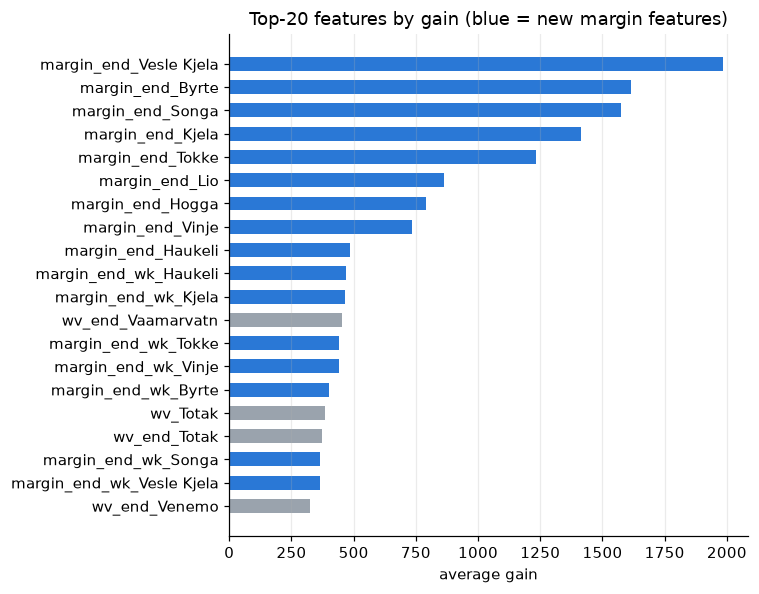

In [6]:
imp = pd.Series(res["model"].get_booster().get_score(importance_type="gain")).sort_values().tail(20)
colors = [BLUE if c.startswith("margin") else "#9aa3ad" for c in imp.index]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(imp.index, imp.values, color=colors, height=0.6)
ax.set_xlabel("average gain"); ax.set_title("Top-20 features by gain (blue = new margin features)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 4. Refit on all years and write the submission

In [7]:
t0 = time.time()
final_model = xgb.XGBClassifier(n_estimators=res["n_rounds"], tree_method="hist", device=DEVICE, random_state=SEED, **params).fit(X, Y)
print(f"refit on {len(uc)} cases with {res['n_rounds']} rounds in {time.time() - t0:.0f}s")

X_test = add_margin_features(build_base(test_map["starttime"]))
submission = to_wide(final_model.predict_proba(X_test), test_map["Run No"])
assert list(submission.columns) == list(sample.columns)
vals = submission[label_cols].to_numpy()
assert ((vals >= 0) & (vals <= 1)).all()

fname = f"submission_xgb_tuned_cv{res['report_auc']:.4f}.csv"
submission.to_csv(fname, index=False)
print("saved", fname, submission.shape)

refit on 2922 cases with 423 rounds in 61s


saved submission_xgb_tuned_cv0.9806.csv (725, 2353)
